# Qwen3-Embedding + Qwen3-Reranker: retrieve-then-rerank search (CPU)

The two models are built to work as a **two-stage search pipeline**, the standard setup behind semantic search and RAG
(retrieval-augmented generation: finding the right passages to give an LLM):

```
query ──► [1] Qwen3-Embedding: query → vector, compare with pre-computed document vectors ──► top 10 candidates (fast)
                                                                                                   │
          [2] Qwen3-Reranker: read (query, candidate) together, score "does it answer?" ◄─────────┘ (slow, precise)
                                                                                                   │
                                                                                         re-ordered results
```

| | Qwen3-Embedding-0.6B | Qwen3-Reranker-0.6B |
|---|---|---|
| Type | **bi-encoder**: query and document are encoded **separately** | **cross-encoder**: query and document are read **together** |
| Output | a 1024-number vector per text; relevance = cosine similarity | one relevance score 0–1 per (query, document) pair |
| Speed | documents are embedded **once** and stored, so search is a fast vector lookup | must run once **per pair, per query**, so only feasible on a short list |
| Role | **recall**: find candidates among thousands/millions | **precision**: put the best ones on top |
| CPU here | ~1–3 s per 256-token document (one-time, then cached), ~0.3 s per query | **~3.3 s per (query, document) pair**, so ~33 s per query for 10 candidates |

Both are 0.6B parameters (~2.4 GB RAM each in float32), Apache-2.0 and multilingual (100+ languages, incl. Tagalog).
To fit a 7 GB laptop, this notebook **never holds both models at once**: it embeds everything, saves the vectors, unloads the embedder, then loads the reranker.

> **Qwen3-Embedding: what it does.** It's built on the Qwen3 language model. It reads a text and keeps the hidden state of the **last token** as a
> 1024-dimensional vector, normalised to length 1. Texts with similar meaning get vectors pointing the same way, so the dot product (= cosine similarity) measures relevance.
>
> | | |
> |---|---|
> | **Input** | text. **Queries** get a one-line task instruction: `"Instruct: Given a scientific claim, retrieve documents that support or refute the claim\nQuery:<text>"`. **Documents** don't. |
> | **Output** | a vector of 1024 floats per text (can be cut to 512/256/128 dims: "Matryoshka" embeddings, section 1c) |
> | **Needs from you** | a task instruction for queries, and somewhere to store document vectors (a numpy array here, a vector database at scale) |
>
> **Qwen3-Reranker: what it does.** It's a Qwen3 chat model asked a yes/no question: *"Judge whether the Document meets the requirements based on the Query and the Instruct.
> Answer yes or no."* The relevance score is the model's **probability of answering "yes"**.
>
> | | |
> |---|---|
> | **Input** | (instruction, query, document) formatted into one prompt |
> | **Output** | a score from 0 to 1 per pair (e.g. 0.98 = clearly relevant, 0.01 = not) |
> | **Needs from you** | the candidate list to score (from stage 1). Cost grows with candidates × queries. |

In [1]:
import ctypes, gc, json, os, time, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import display
from transformers import AutoModel, AutoModelForCausalLM, AutoTokenizer
from transformers.utils import logging as hf_logging

warnings.filterwarnings("ignore"); hf_logging.set_verbosity_error()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
print("device:", DEVICE, "| torch", torch.__version__, "| threads", torch.get_num_threads())
DATA = Path("data"); OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 110)

def rss_mb():
    return int(open(f"/proc/{os.getpid()}/status").read().split("VmRSS:")[1].split()[0]) // 1024

def release_memory():
    # gc alone leaves freed tensors inside the C allocator; malloc_trim hands that memory back to the OS (Linux)
    gc.collect()
    try: ctypes.CDLL("libc.so.6").malloc_trim(0)
    except OSError: pass

/home/tsubame/miniconda3/envs/ocr/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cpu | torch 2.15.0+cpu | threads 4


## Settings

In [2]:
EMBED_ID = "Qwen/Qwen3-Embedding-0.6B"
RERANK_ID = "Qwen/Qwen3-Reranker-0.6B"
DOC_MAX_TOKENS = 256      # documents are cut to this length (keeps CPU time down; abstracts' key claims are usually early)
TOP_K = 10                # stage 1 hands this many candidates to the reranker
BATCH = 8
TASK = "Given a scientific claim, retrieve documents that support or refute the claim"
MINI_TASK = "Given a question, retrieve passages that answer it"

## Stage 1: the embedding model

In [3]:
t = time.time()
emb_tok = AutoTokenizer.from_pretrained(EMBED_ID, padding_side="left")
emb_model = AutoModel.from_pretrained(EMBED_ID, dtype=DTYPE).to(DEVICE).eval()
print(f"{EMBED_ID}: {sum(p.numel() for p in emb_model.parameters()) / 1e6:.0f}M params, loaded in {time.time() - t:.1f}s")

@torch.no_grad()
def embed(texts, task=None, max_tokens=DOC_MAX_TOKENS, batch=BATCH, desc=""):
    if task:                                   # queries get the instruction, documents don't
        texts = [f"Instruct: {task}\nQuery:{q}" for q in texts]
    vecs, t = [], time.time()
    for i in range(0, len(texts), batch):
        b = emb_tok(texts[i:i + batch], padding=True, truncation=True, max_length=max_tokens, return_tensors="pt").to(DEVICE)
        h = emb_model(**b).last_hidden_state[:, -1]          # left padding -> last position is the last real token
        vecs.append(F.normalize(h.float(), dim=-1).cpu())
        if desc and (i // batch) % 10 == 0:
            print(f"  {desc}: {min(i + batch, len(texts))}/{len(texts)} ({time.time() - t:.0f}s)", flush=True)
    return torch.cat(vecs).numpy()

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/310 [00:00<00:46,  6.71it/s]

Loading weights:  61%|██████▏   | 190/310 [00:00<00:00, 904.65it/s]

Loading weights:  95%|█████████▌| 296/310 [00:00<00:00, 834.58it/s]

Loading weights: 100%|██████████| 310/310 [00:00<00:00, 745.03it/s]

Qwen/Qwen3-Embedding-0.6B: 596M params, loaded in 3.8s


### 1a. A small walkthrough: 12 passages in English and Tagalog

The same vectors work **across languages**: a Tagalog question can find an English passage and vice versa.

embedded 12 passages + 6 queries in 5.3s; vector size 1024


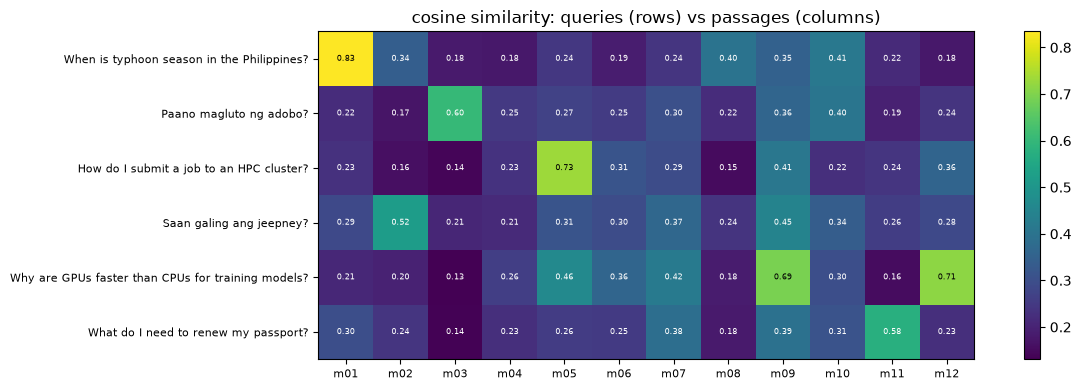

Q: When is typhoon season in the Philippines?
   → [m01 0.83] Typhoon season in the Philippines usually runs from June to November, when most tropical cyclones enter the Ph
Q: Paano magluto ng adobo?
   → [m03 0.60] Chicken adobo is cooked by simmering chicken in vinegar, soy sauce, garlic, bay leaves and black peppercorns.
Q: How do I submit a job to an HPC cluster?
   → [m05 0.73] To run a batch job on a SLURM cluster, write a job script with #SBATCH options for time, memory and GPUs, then
Q: Saan galing ang jeepney?
   → [m02 0.52] Ang jeepney ay isang pampublikong sasakyan sa Pilipinas na nagmula sa mga lumang jeep ng militar ng Amerika pa
Q: Why are GPUs faster than CPUs for training models?
   → [m12 0.71] A GPU speeds up deep learning because it performs thousands of matrix multiplications in parallel, unlike a CP
Q: What do I need to renew my passport?
   → [m11 0.58] Para mag-renew ng pasaporte, kailangang mag-book ng appointment online, dalhin ang lumang pasaporte, at magbay


In [4]:
MINI = pd.read_json(DATA / "mini_corpus.jsonl", lines=True)
MINI_Q = ["When is typhoon season in the Philippines?",
          "Paano magluto ng adobo?",                              # Tagalog: "How do you cook adobo?"
          "How do I submit a job to an HPC cluster?",
          "Saan galing ang jeepney?",                             # Tagalog: "Where did the jeepney come from?"
          "Why are GPUs faster than CPUs for training models?",
          "What do I need to renew my passport?"]
t = time.time()
mini_doc_vecs = embed(MINI.text.tolist())
mini_q_vecs = embed(MINI_Q, task=MINI_TASK)
print(f"embedded {len(MINI)} passages + {len(MINI_Q)} queries in {time.time() - t:.1f}s; vector size {mini_doc_vecs.shape[1]}")

sims = mini_q_vecs @ mini_doc_vecs.T
fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(sims, cmap="viridis")
ax.set_yticks(range(len(MINI_Q)), MINI_Q, fontsize=8); ax.set_xticks(range(len(MINI)), MINI.id, fontsize=8)
for i in range(sims.shape[0]):
    for j in range(sims.shape[1]):
        ax.text(j, i, f"{sims[i, j]:.2f}", ha="center", va="center", fontsize=6, color="white" if sims[i, j] < sims.max() * 0.8 else "black")
ax.set_title("cosine similarity: queries (rows) vs passages (columns)"); plt.colorbar(im); plt.tight_layout(); plt.show()

MINI_TOP = {q: list(np.argsort(-sims[i])[:3]) for i, q in enumerate(MINI_Q)}
for i, q in enumerate(MINI_Q):
    j = MINI_TOP[q][0]
    print(f"Q: {q}\n   → [{MINI.id[j]} {sims[i, j]:.2f}] {MINI.text[j][:110]}")

### 1b. Embed the SciFact collection (300 abstracts, 30 claims)

SciFact is a public search benchmark: each query is a scientific **claim**, and human annotators marked which paper abstracts support or refute it.
Here the collection has 300 abstracts: 33 relevant to the 30 claims, plus 267 random distractors.
The document vectors are cached in `outputs/`, so this slow step only runs once.

In [5]:
DOCS = pd.read_json(DATA / "scifact_corpus.jsonl", lines=True, dtype={"_id": str})
QUERIES = pd.read_json(DATA / "scifact_queries.jsonl", lines=True, dtype={"_id": str})
QRELS = pd.read_csv(DATA / "scifact_qrels.tsv", sep="\t", dtype=str)
RELEVANT = QRELS.groupby("query-id")["corpus-id"].apply(set).to_dict()
DOC_TEXT = (DOCS.title + ". " + DOCS.text).tolist()
print(f"{len(DOCS)} documents, {len(QUERIES)} queries, {len(QRELS)} relevance judgements")
print("example claim:", QUERIES.text[0])

cache = OUT / f"scifact_doc_vectors_{DOC_MAX_TOKENS}.npy"
t = time.time()
if cache.exists():
    DOC_VECS = np.load(cache); print(f"loaded cached document vectors {DOC_VECS.shape}")
else:
    DOC_VECS = embed(DOC_TEXT, desc="documents"); np.save(cache, DOC_VECS)
EMBED_DOC_S = time.time() - t
t = time.time()
Q_VECS = embed(QUERIES.text.tolist(), task=TASK)
EMBED_Q_S = time.time() - t
print(f"documents: {EMBED_DOC_S:.0f}s ({EMBED_DOC_S / len(DOCS):.2f}s each) | queries: {EMBED_Q_S:.1f}s ({EMBED_Q_S / len(QUERIES):.2f}s each)")

300 documents, 30 queries, 33 relevance judgements
example claim: Alizarin forms hydrogen bonds with residues involved in PGAM1 substrate binding.
loaded cached document vectors (300, 1024)


documents: 0s (0.00s each) | queries: 10.2s (0.34s each)


### Stage 1 results: retrieval with vectors only

For each claim: compute the cosine similarity with all 300 abstracts and take the top 10.
- **Recall@k:** the share of relevant abstracts that are in the top k.
- **MRR@10:** 1 / rank of the first relevant hit (1.0 = always ranked first).
- **nDCG@10:** a ranking-quality score that rewards relevant items near the top.

In [6]:
def metrics(ranked_ids, qid):
    rel = RELEVANT[qid]
    hits = [d in rel for d in ranked_ids[:10]]
    dcg = sum(h / np.log2(i + 2) for i, h in enumerate(hits))
    idcg = sum(1 / np.log2(i + 2) for i in range(min(len(rel), 10)))
    first = next((i for i, h in enumerate(hits) if h), None)
    return {"recall@1": sum(hits[:1]) / len(rel), "recall@3": sum(hits[:3]) / len(rel), "recall@10": sum(hits) / len(rel),
            "MRR@10": 0 if first is None else 1 / (first + 1), "nDCG@10": dcg / idcg}

t = time.time()
S = Q_VECS @ DOC_VECS.T                                  # (30 queries x 300 docs) similarity matrix
TOPK = np.argsort(-S, axis=1)[:, :TOP_K]
SEARCH_S = time.time() - t
stage1 = {q: [DOCS._id[j] for j in TOPK[i]] for i, q in enumerate(QUERIES._id)}
M1 = pd.DataFrame([metrics(stage1[q], q) for q in QUERIES._id]).mean()
print(f"vector search for {len(QUERIES)} queries over {len(DOCS)} docs: {1000 * SEARCH_S:.1f} ms total")
display(M1.to_frame("embedding only").T.style.format("{:.3f}"))

vector search for 30 queries over 300 docs: 17.1 ms total


,recall@1,recall@3,recall@10,MRR@10,nDCG@10
embedding only,0.861,0.933,1.000,0.932,0.948


### 1c. Smaller vectors ("Matryoshka" embeddings)

Qwen3-Embedding is trained so that the **first N numbers** of the vector are already a usable embedding.
Cutting 1024 → 256 dims uses 4× less storage in a vector database, usually at a small accuracy cost.

In [7]:
rows = []
for dims in [1024, 512, 256, 128, 64]:
    d = F.normalize(torch.tensor(DOC_VECS[:, :dims]), dim=-1).numpy()
    q = F.normalize(torch.tensor(Q_VECS[:, :dims]), dim=-1).numpy()
    top = np.argsort(-(q @ d.T), axis=1)[:, :10]
    m = pd.DataFrame([metrics([DOCS._id[j] for j in top[i]], qid) for i, qid in enumerate(QUERIES._id)]).mean()
    rows.append({"dims": dims, "storage per doc (float32)": f"{dims * 4} bytes", **m[["recall@10", "nDCG@10"]].round(3).to_dict()})
display(pd.DataFrame(rows).set_index("dims"))

,storage per doc (float32),recall@10,nDCG@10
dims,,,
1024,4096 bytes,1.000,0.948
512,2048 bytes,1.000,0.914
256,1024 bytes,0.967,0.894
128,512 bytes,0.933,0.807
64,256 bytes,0.900,0.751


Unload the embedding model before loading the reranker. `del` + garbage collection alone only gave back ~0.9 of ~2.4 GB in testing
(the C memory allocator keeps freed blocks), and the notebook ran out of memory. `malloc_trim` returns them to the OS.

In [8]:
before = rss_mb()
del emb_model; release_memory()
print(f"embedding model unloaded: process memory {before} MB -> {rss_mb()} MB")

embedding model unloaded: process memory 3044 MB -> 687 MB


## Stage 2: the reranker

In [9]:
t = time.time()
rr_tok = AutoTokenizer.from_pretrained(RERANK_ID, padding_side="left")
rr_model = AutoModelForCausalLM.from_pretrained(RERANK_ID, dtype=DTYPE).to(DEVICE).eval()
print(f"{RERANK_ID}: {sum(p.numel() for p in rr_model.parameters()) / 1e6:.0f}M params, loaded in {time.time() - t:.1f}s")

YES, NO = rr_tok.convert_tokens_to_ids("yes"), rr_tok.convert_tokens_to_ids("no")
PREFIX = ("<|im_start|>system\nJudge whether the Document meets the requirements based on the Query and the Instruct provided. "
          "Note that the answer can only be \"yes\" or \"no\".<|im_end|>\n<|im_start|>user\n")
SUFFIX = "<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n"

@torch.no_grad()
def rerank_scores(query, docs, task=TASK, batch=BATCH):
    # docs are cut to DOC_MAX_TOKENS so stage 2 sees the same text as stage 1
    docs = [rr_tok.decode(rr_tok(d, add_special_tokens=False).input_ids[:DOC_MAX_TOKENS]) for d in docs]
    prompts = [f"{PREFIX}<Instruct>: {task}\n<Query>: {query}\n<Document>: {d}{SUFFIX}" for d in docs]
    scores = []
    for i in range(0, len(prompts), batch):
        b = rr_tok(prompts[i:i + batch], padding=True, return_tensors="pt", add_special_tokens=False).to(DEVICE)
        logits = rr_model(**b).logits[:, -1, [NO, YES]].float()
        scores += torch.softmax(logits, dim=-1)[:, 1].tolist()   # P("yes")
    return scores

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/310 [00:00<00:33,  9.24it/s]

Loading weights:  61%|██████▏   | 190/310 [00:00<00:00, 1062.08it/s]

Loading weights:  96%|█████████▋| 299/310 [00:00<00:00, 997.43it/s] 

Loading weights: 100%|██████████| 310/310 [00:00<00:00, 912.60it/s]

Qwen/Qwen3-Reranker-0.6B: 596M params, loaded in 2.3s


### 2a. Walkthrough: rerank the mini collection's top 3

The embedding stage found 3 candidates for each question. The reranker now scores each (question, passage) pair directly.

In [10]:
rows = []
for q, cand in MINI_TOP.items():
    scores = rerank_scores(q, MINI.text[cand].tolist(), task=MINI_TASK)
    for rank, (j, s) in enumerate(sorted(zip(cand, scores), key=lambda x: -x[1])):
        rows.append({"query": q if rank == 0 else "", "passage": f"[{MINI.id[j]}] {MINI.text[j][:80]}…",
                     "embedding cos": round(float(sims[MINI_Q.index(q), j]), 3), "reranker P(yes)": round(s, 3)})
display(pd.DataFrame(rows))

,query,passage,embedding cos,reranker P(yes)
0,When is typhoon season in the Philippines?,"[m01] Typhoon season in the Philippines usually runs from June to November, when most …",0.835,0.999
1,,[m08] Ang Bulkang Mayon sa Albay ay kilala sa halos perpektong hugis-kono nito at isa …,0.398,0.001
2,,[m10] Rice terraces in Banaue were carved into the mountains of Ifugao by hand more th…,0.413,0.000
3,Paano magluto ng adobo?,"[m03] Chicken adobo is cooked by simmering chicken in vinegar, soy sauce, garlic, bay …",0.602,0.738
4,,[m10] Rice terraces in Banaue were carved into the mountains of Ifugao by hand more th…,0.403,0.000
5,,[m09] Learning rate controls how big each update step is when training a neural networ…,0.360,0.000
6,How do I submit a job to an HPC cluster?,"[m05] To run a batch job on a SLURM cluster, write a job script with #SBATCH options f…",0.731,0.996
7,,[m12] A GPU speeds up deep learning because it performs thousands of matrix multiplica…,0.359,0.002
8,,[m09] Learning rate controls how big each update step is when training a neural networ…,0.410,0.000
9,Saan galing ang jeepney?,[m02] Ang jeepney ay isang pampublikong sasakyan sa Pilipinas na nagmula sa mga lumang…,0.520,0.993


Note the different scales: cosine similarities sit in a narrow band (e.g. 0.3–0.7) and only their *order* matters,
whereas the reranker gives near-binary judgements (≈1 = answers the question, ≈0 = doesn't). That makes reranker scores usable as a **cut-off**
(e.g. "only pass documents with P(yes) > 0.5 to the LLM").

### 2b. Rerank SciFact: top 10 per claim

In [11]:
stage2, RR_SCORES, t = {}, {}, time.time()
for i, (qid, qtext) in enumerate(zip(QUERIES._id, QUERIES.text)):
    cand = stage1[qid]
    texts = [DOC_TEXT[DOCS.index[DOCS._id == d][0]] for d in cand]
    scores = rerank_scores(qtext, texts)
    RR_SCORES[qid] = dict(zip(cand, scores))
    stage2[qid] = [d for d, _ in sorted(zip(cand, scores), key=lambda x: -x[1])]
    if i % 5 == 0:
        print(f"  {i + 1}/{len(QUERIES)} queries reranked ({time.time() - t:.0f}s)", flush=True)
RERANK_S = time.time() - t
M2 = pd.DataFrame([metrics(stage2[q], q) for q in QUERIES._id]).mean()
print(f"reranked {len(QUERIES)} x {TOP_K} = {len(QUERIES) * TOP_K} pairs in {RERANK_S:.0f}s ({RERANK_S / (len(QUERIES) * TOP_K):.2f}s per pair)")

COMPARE = pd.DataFrame({"embedding only": M1, f"embedding + reranker (top {TOP_K})": M2}).T
display(COMPARE.style.format("{:.3f}").highlight_max(axis=0, props="font-weight:bold"))

  1/30 queries reranked (32s)


  6/30 queries reranked (191s)


  11/30 queries reranked (356s)


  16/30 queries reranked (518s)


  21/30 queries reranked (688s)


  26/30 queries reranked (857s)


reranked 30 x 10 = 300 pairs in 993s (3.31s per pair)


,recall@1,recall@3,recall@10,MRR@10,nDCG@10
embedding only,0.861,0.933,1.000,0.932,0.948
embedding + reranker (top 10),0.961,1.000,1.000,1.000,1.000


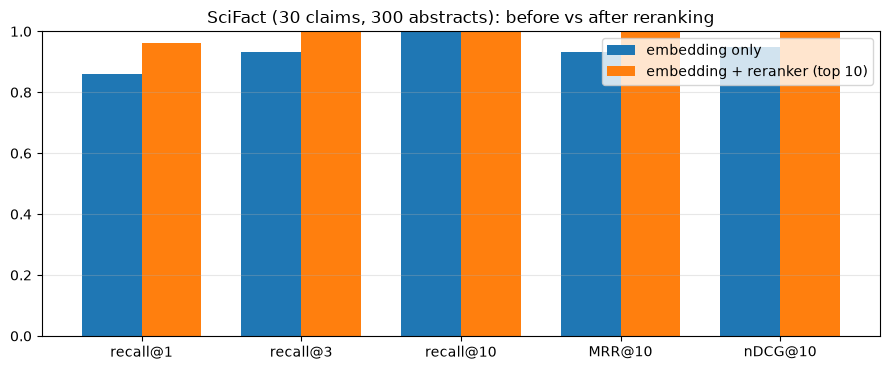

note: recall@10 can't change. The reranker only re-orders the 10 candidates it is given; it can't find documents stage 1 missed.


In [12]:
ax = COMPARE.T.plot.bar(figsize=(9, 3.8), rot=0, width=0.75)
ax.set_ylim(0, 1); ax.set_title("SciFact (30 claims, 300 abstracts): before vs after reranking"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(OUT / "rerank_comparison.png", dpi=100); plt.show()
print("note: recall@10 can't change. The reranker only re-orders the 10 candidates it is given; it can't find documents stage 1 missed.")

### Where the reranker changed the answer

In [13]:
moved = []
for qid, qtext in zip(QUERIES._id, QUERIES.text):
    rel = RELEVANT[qid]
    r1 = next((i + 1 for i, d in enumerate(stage1[qid]) if d in rel), None)
    r2 = next((i + 1 for i, d in enumerate(stage2[qid]) if d in rel), None)
    moved.append({"claim": qtext, "rank before": r1, "rank after": r2})
MOVED = pd.DataFrame(moved)
MOVED["change"] = np.where(MOVED["rank before"].isna(), "not in top 10",
                  np.where(MOVED["rank after"] < MOVED["rank before"], "improved",
                  np.where(MOVED["rank after"] > MOVED["rank before"], "worse", "same")))
print(MOVED.change.value_counts().to_string()); MOVED.to_csv(OUT / "rank_changes.csv", index=False)
display(MOVED[MOVED.change.isin(["improved", "worse"])].sort_values("change"))

change
same        27
improved     3


,claim,rank before,rank after,change
9,FoxO3a activation in neuronal death is mediated by reactive oxygen species (ROS).,4,1,improved
19,Mercaptopurine is anabolized into the inactive methylmercaptopurine by thiopurine methyltrasnferase (TPMT).,2,1,improved
21,N-terminal cleavage increases success identifying transcription start sites.,5,1,improved


In [14]:
ex = MOVED[MOVED.change == "improved"].iloc[0] if (MOVED.change == "improved").any() else MOVED.iloc[0]
qid = QUERIES._id[QUERIES.text == ex.claim].iloc[0]
print("CLAIM:", ex.claim, "\n")
for label, ranking in [("embedding only", stage1[qid]), ("after reranker", stage2[qid])]:
    print(f"--- {label} ---")
    for r, d in enumerate(ranking[:3], 1):
        title = DOCS.title[DOCS._id == d].iloc[0]
        star = "★ relevant" if d in RELEVANT[qid] else ""
        print(f"  {r}. P(yes)={RR_SCORES[qid][d]:.3f}  {title[:95]}  {star}")

CLAIM: FoxO3a activation in neuronal death is mediated by reactive oxygen species (ROS). 

--- embedding only ---


  1. P(yes)=0.082  Monitoring starvation-induced reactive oxygen species formation.  
  2. P(yes)=0.017  Phosphorylation of ATM by Cdk5 mediates DNA damage signaling and regulates neuronal death  
  3. P(yes)=0.000  Ncf1 (p47phox) Is Essential for Direct Regulatory T Cell Mediated Suppression of CD4+ Effector   
--- after reranker ---
  1. P(yes)=0.117  Stress-dependent regulation of FOXO transcription factors by the SIRT1 deacetylase.  ★ relevant
  2. P(yes)=0.082  Monitoring starvation-induced reactive oxygen species formation.  
  3. P(yes)=0.017  Phosphorylation of ATM by Cdk5 mediates DNA damage signaling and regulates neuronal death  


## 3. End-to-end `search()` for your own questions

`search()` runs both stages for a new query over the SciFact collection (or your own `DOCS`).
Stage 1 needs the embedding model again; because RAM is tight, it is loaded only for the query, then unloaded.
On a machine with ~6 GB free, set `KEEP_BOTH = True` to keep both models loaded and make repeated searches faster.

In [15]:
KEEP_BOTH = False
_emb = {"model": None}

def search(query, top_k=TOP_K, show=5):
    t0 = time.time()
    global emb_model
    if _emb["model"] is None:
        emb_model = AutoModel.from_pretrained(EMBED_ID, dtype=DTYPE).to(DEVICE).eval(); _emb["model"] = emb_model
    qv = embed([query], task=TASK)[0]
    if not KEEP_BOTH:
        del emb_model; _emb["model"] = None; release_memory()
    t1 = time.time()
    cand = np.argsort(-(DOC_VECS @ qv))[:top_k]
    scores = rerank_scores(query, [DOC_TEXT[j] for j in cand])
    order = sorted(zip(cand, scores), key=lambda x: -x[1])
    print(f"query: {query!r}  (embed {t1 - t0:.1f}s incl. model load, rerank {time.time() - t1:.1f}s)")
    return pd.DataFrame([{"rank": r, "P(yes)": round(s, 3), "cosine": round(float(DOC_VECS[j] @ qv), 3),
                          "title": DOCS.title[j]} for r, (j, s) in enumerate(order[:show], 1)])

display(search("Does vitamin D supplementation reduce the risk of fractures?"))

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights:  11%|█▏        | 35/310 [00:00<00:00, 316.59it/s]

Loading weights:  22%|██▏       | 67/310 [00:00<00:00, 255.74it/s]

Loading weights:  30%|███       | 94/310 [00:01<00:02, 73.29it/s] 

Loading weights:  35%|███▌      | 110/310 [00:01<00:02, 79.78it/s]

Loading weights:  40%|████      | 124/310 [00:01<00:02, 73.53it/s]

... (6 outputs left out)

Loading weights:  97%|█████████▋| 300/310 [00:02<00:00, 127.46it/s]

Loading weights: 100%|██████████| 310/310 [00:02<00:00, 104.39it/s]

query: 'Does vitamin D supplementation reduce the risk of fractures?'  (embed 11.0s incl. model load, rerank 33.1s)


,rank,P(yes),cosine,title
0,1,0.083,0.537,HMG-CoA reductase inhibitors and the risk of hip fractures in elderly patients.
1,2,0.031,0.553,"Relationship between serum parathyroid hormone levels, vitamin D sufficiency, and calcium intake."
2,3,0.009,0.374,Internal fixation versus nonoperative treatment of displaced 3-part proximal humeral fractures in elderly ...
3,4,0.000,0.360,"Past exposure to sun, skin phenotype, and risk of multiple sclerosis: case-control study."
4,5,0.000,0.367,Effect of physical activity on cognitive function in older adults at risk for Alzheimer disease: a randomi...



**What this run showed (CPU):**
- **Cross-language retrieval works:** all 6 walkthrough questions found the right passage first, including Tagalog questions → English passages
  ("Paano magluto ng adobo?" → the adobo recipe) and the English passport question → the Tagalog passport passage.
- **Reranker scores are decisive:** relevant passages got P(yes) 0.74–0.999 and the rest ≤ 0.002, while cosine similarities sat in a narrow 0.36–0.83 band.
  So reranker scores work as a cut-off ("only send P(yes) > 0.5 to the LLM").
- **SciFact (30 claims, 300 abstracts):** embedding alone was already strong (recall@1 0.86, nDCG@10 0.95; every relevant abstract was in the top 10).
  **Reranking made it perfect on this set:** recall@1 0.96, MRR and nDCG 1.00. It moved the right abstract to rank 1 for 3 claims (from ranks 2, 4 and 5) and never made a ranking worse.
  With only 300 documents this is an easy setting; on millions of documents both stages matter more.
- **Smaller vectors:** 512 dims kept recall@10 at 1.00 (nDCG 0.95 → 0.91) at half the storage. 256 dims still found 97%.
- **The `search()` example has no good answer in this collection** (no vitamin-D/fracture trial among the 300 abstracts). The reranker shows that:
  the best P(yes) was only 0.08. Cosine similarity alone (0.54–0.55) would not have told you.
- **Speed is the trade-off:** a vector search over 300 docs took ~1 ms per query, but reranking 10 candidates took ~33 s on this CPU (3.3 s per pair).
  On a GPU this drops to well under a second, which is why rerankers are usually run on a GPU and on a short candidate list.
- **Memory:** to fit 7 GB of RAM, models are loaded one at a time, and `malloc_trim` is needed to really release the first one (3,044 MB → 687 MB).
- In the summary table, "embed 300 documents" shows 0 s because the vectors were loaded from the cache. Computing them the first time takes several minutes on CPU.


## 4. Summary

In [16]:
summary = pd.DataFrame([
    {"step": "embed 300 documents (one-time, cached)", "seconds": EMBED_DOC_S, "per item": EMBED_DOC_S / len(DOCS)},
    {"step": f"embed {len(QUERIES)} queries", "seconds": EMBED_Q_S, "per item": EMBED_Q_S / len(QUERIES)},
    {"step": "vector search (all queries)", "seconds": SEARCH_S, "per item": SEARCH_S / len(QUERIES)},
    {"step": f"rerank {len(QUERIES)} x {TOP_K} pairs", "seconds": RERANK_S, "per item": RERANK_S / (len(QUERIES) * TOP_K)},
])
display(summary.style.format({"seconds": "{:.1f}", "per item": "{:.3f}"}))
COMPARE.round(4).to_csv(OUT / "metrics.csv")
display(COMPARE.style.format("{:.3f}"))

,step,seconds,per item
0,"embed 300 documents (one-time, cached)",0.0,0.000
1,embed 30 queries,10.2,0.342
2,vector search (all queries),0.0,0.001
3,rerank 30 x 10 pairs,992.7,3.309


,recall@1,recall@3,recall@10,MRR@10,nDCG@10
embedding only,0.861,0.933,1.000,0.932,0.948
embedding + reranker (top 10),0.961,1.000,1.000,1.000,1.000
